In [1]:
# --- arranque en Colab (no hace nada fuera de Colab) -----------------------
# Colab arranca en /content con un entorno vacío: sin esta celda el
# `import environment` siguiente falla con ModuleNotFoundError. Generada por
# tools/py_to_notebook.py -- editala ahí, no acá.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/solidgoldmagickarp/proyecto_de_lenguaje_emergente.git"
    REPO_DIR = "proyecto_de_lenguaje_emergente"

    # El orden de las guardas importa: primero probar DÓNDE estamos, después qué hay en disco.
    # `isdir(REPO_DIR)` es relativo, así que chequearlo primero clonaría una copia
    # anidada en cualquier re-ejecución de esta celda dentro de la misma sesión (algo rutinario).
    if os.path.basename(os.getcwd()) != REPO_DIR:
        if not os.path.isdir(REPO_DIR):
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
        os.chdir(REPO_DIR)
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True
    )

    # El disco de Colab es EFÍMERO: cada checkpoint se pierde cuando el entorno de ejecución
    # se desconecta (~90 min de inactividad en el plan gratuito), y las Etapas 3, 4 y 5 necesitan
    # todas los checkpoints de la Etapa 2. Descomentá para guardarlos en Drive en su lugar.
    #
    # Notar `islink`, no `exists`: importar `environment` crea un directorio checkpoints/
    # REAL, y `exists` entonces saltearía el enlace en silencio y mandaría cada
    # checkpoint de vuelta al disco efímero.
    #
    # from google.colab import drive
    # drive.mount("/content/drive")
    # PERSISTENT = "/content/drive/MyDrive/proyecto_de_lenguaje_emergente/checkpoints"
    # os.makedirs(PERSISTENT, exist_ok=True)
    # if os.path.islink("checkpoints"):
    #     print("checkpoints ->", os.readlink("checkpoints"))
    # elif os.path.isdir("checkpoints"):
    #     print("ADVERTENCIA: checkpoints/ ya es un directorio real, así que NO está en Drive.")
    #     print("Mové su contenido a", PERSISTENT, ", borralo, y volvé a ejecutar esta celda.")
    # else:
    #     os.symlink(PERSISTENT, "checkpoints")
    #     print("checkpoints ->", PERSISTENT)

    print("Arranque en Colab OK. Directorio de trabajo:", os.getcwd())

# Etapa 4 · SFT — comportamiento, no conocimiento

Seguimos entrenando el modelo ancho de la Etapa 2 sobre TinyStories-Instruct, con la misma pérdida de próximo
token. Lo único que cambia son los datos: bloques `encabezado de instrucción → Story: → cuento`.

Dos decisiones de implementación que conviene tener presentes al leer los resultados:

- **Batches alineados al ejemplo.** En el preentrenamiento las ventanas caen en cualquier lugar del corpus. Acá
  cada fila del batch arranca en el comienzo de un registro, así el modelo siempre ve la instrucción entera antes
  del cuento. Lo que no entra en `block_size` se trunca; lo que sobra se rellena y queda fuera de la pérdida.
- **La pérdida incluye el encabezado.** Es el formato de continuación pelado que describe la consigna; no se
  enmascaran los tokens de la instrucción.

Escribe `checkpoints/sft_final.pt` (fine-tuning completo) y, si `DO_LORA`, `checkpoints/sft_lora.pt` (con el
adaptador ya fusionado en los pesos, para que se cargue como cualquier otro modelo).

In [2]:
import environment  # noqa: F401

environment.summary()

SMOKE_TEST = False
RETRAIN = False
DO_LORA = True
SEED = 1337

DEVICE = environment.device()
SFT_RECORDS = 1_000 if SMOKE_TEST else 100_000
VAL_RECORDS = 200 if SMOKE_TEST else 2_000
BATCH_SIZE = 16 if SMOKE_TEST else 64
MAX_STEPS = 100 if SMOKE_TEST else 2_000
LR = 1e-4
LORA_RANK, LORA_ALPHA, LORA_LR = 8, 16, 1e-3
EVAL_INTERVAL = 25 if SMOKE_TEST else 200
EVAL_ITERS = 10 if SMOKE_TEST else 40
N_EVAL_PROMPTS = 10 if SMOKE_TEST else 100

ENTORNO
os             : Windows 11
python         : 3.13.15
venv           : C:\dev\ia-generativa-sistemas-multiagente\tp\1\proyecto_de_lenguaje_emergente\.venv
cpu            : Intel64 Family 6 Model 158 Stepping 10, GenuineIntel
logical_cores  : 6
torch          : 2.11.0+cu128
torch_threads  : 6
cuda_available : True
gpu            : NVIDIA GeForce RTX 3050
gpu_memory_gb  : 6.44
ram_total_gb   : 17.1
ram_free_gb    : 5.2
--------------------------------------------------------------
HF_HOME        : C:\Users\juani\.cache\huggingface
ca_bundle      : no presente (normal)


## Datos

`load_instruct_records` reagrupa el dataset de una-línea-por-fila en registros completos. La primera vez tarda:
materializa el split entero antes de cortar (ver `data.py`).

In [3]:
import json
import re
from pathlib import Path

import numpy as np
import torch
from tokenizers import Tokenizer

from data import load_instruct_records
from lab import EOS_TOKEN

tokenizer = Tokenizer.from_file("checkpoints/tokenizer.json")
EOS_ID = tokenizer.token_to_id(EOS_TOKEN)

train_records = load_instruct_records("train", limit=SFT_RECORDS)
val_records = load_instruct_records("validation", limit=VAL_RECORDS + N_EVAL_PROMPTS)
eval_records, val_records = val_records[:N_EVAL_PROMPTS], val_records[N_EVAL_PROMPTS:]
print(f"registros: train {len(train_records):,} | val {len(val_records):,} | prompts de evaluación {len(eval_records):,}")
print("\n--- un registro, tal cual entra al modelo ---")
print(repr(train_records[0][:400]))

registros: train 100,000 | val 2,000 | prompts de evaluación 100

--- un registro, tal cual entra al modelo ---
'Features: Dialogue\nWords: quit, oak, gloomy\nSummary: Sara and Ben were playing in the park, but Sara wanted to go home because it was cold and dark. Ben convinced her to stay and play, but eventually agreed to go home and have hot cocoa.\nStory: \n\nSara and Ben were playing in the park. They liked to climb the big oak tree and pretend they were birds. They made nests with leaves and twigs and sang s'


In [4]:
# MEDIDO sobre el dataset (no asumido): conviven dos formatos. ~55% trae "Story: \n\n<cuento>" y ~45% trae
# "Story: <cuento>" en la misma línea; y en algunos registros un campo (típicamente Summary:) aparece DESPUÉS
# del cuento. Por eso: `\s*` después de "Story:", y los campos se buscan en cualquier línea del registro.
STORY_SPLIT = re.compile(r"^(.*?Story:[ \t]*\n*)(.*)$", re.DOTALL)
HEADER_KEYS = ("Features", "Words", "Summary", "Random sentence")
FIELD_LINE = re.compile(rf"^({'|'.join(HEADER_KEYS)}):[ \t]*(.*)$", re.MULTILINE)


def split_record(rec):
    """-> (encabezado hasta 'Story:' inclusive, cuento, dict de campos). None si el registro no tiene 'Story:'."""
    m = STORY_SPLIT.match(rec)
    if not m:
        return None
    header, body = m.group(1), m.group(2)
    trailing = FIELD_LINE.search(body)
    story = body[: trailing.start()].rstrip() if trailing else body
    fields = {k: v.strip() for k, v in FIELD_LINE.findall(header)}
    fields.update({k: v.strip() for k, v in FIELD_LINE.findall(body)})
    return header, story, fields


parsed = [split_record(r) for r in train_records]
print(f"registros sin 'Story:': {sum(p is None for p in parsed)}")
print(f"'Story:' con el cuento en la misma línea: {np.mean([not p[0].endswith(chr(10)) for p in parsed if p]):.0%}")
print(f"con algún campo DESPUÉS del cuento: {np.mean([bool(FIELD_LINE.search(r.split('Story:', 1)[1])) for r in train_records if 'Story:' in r]):.0%}")
field_freq = {k: np.mean([k in p[2] for p in parsed if p]) for k in HEADER_KEYS}
print("fracción de registros con cada campo:", {k: f"{v:.0%}" for k, v in field_freq.items()})
orders = {tuple(k for k in [ln.partition(':')[0] for ln in p[0].splitlines()] if k in HEADER_KEYS)
          for p in parsed[:2000] if p}
print(f"órdenes distintos de campos en los primeros 2.000 registros: {len(orders)}")

registros sin 'Story:': 0
'Story:' con el cuento en la misma línea: 52%


con algún campo DESPUÉS del cuento: 30%
fracción de registros con cada campo: {'Features': '55%', 'Words': '67%', 'Summary': '100%', 'Random sentence': '30%'}
órdenes distintos de campos en los primeros 2.000 registros: 65


In [5]:
from lab import load_checkpoint

base_model, base_ckpt = load_checkpoint("checkpoints/pretrain_wide.pt", DEVICE)
BLOCK = base_model.config.block_size


def encode_records(records):
    """Matriz (N, BLOCK+1) alineada al comienzo de cada registro, rellenada con EOS, y el largo real de cada uno."""
    seqs = np.full((len(records), BLOCK + 1), EOS_ID, dtype=np.int32)
    lengths = np.zeros(len(records), dtype=np.int32)
    for k, enc in enumerate(tokenizer.encode_batch(records)):
        ids = (enc.ids + [EOS_ID])[: BLOCK + 1]
        seqs[k, : len(ids)] = ids
        lengths[k] = len(ids)
    return {"seqs": seqs, "lengths": lengths}


def record_batch(data, block_size, batch_size, device, rng):
    ix = rng.integers(0, len(data["seqs"]), size=batch_size)
    seq = torch.from_numpy(data["seqs"][ix].astype(np.int64))
    x, y = seq[:, :-1].clone(), seq[:, 1:].clone()
    # posiciones de relleno: fuera de la pérdida (-100 es el ignore_index por defecto de cross_entropy)
    pad = torch.arange(block_size)[None, :] >= torch.from_numpy(data["lengths"][ix] - 1)[:, None]
    y[pad] = -100
    return x.to(device), y.to(device)


train_data = encode_records(train_records)
val_data = encode_records(val_records)
full_lengths = np.array([len(e.ids) + 1 for e in tokenizer.encode_batch(train_records[:5000])])
print(f"tokens por registro: media {full_lengths.mean():.0f}, p90 {np.percentile(full_lengths, 90):.0f}; "
      f"entran enteros en {BLOCK}: {(full_lengths <= BLOCK + 1).mean():.0%}")

tokens por registro: media 254, p90 324; entran enteros en 192: 14%


## Fine-tuning completo

In [6]:
import copy

from lab import count_params, save_checkpoint, train

# pérdida del modelo base sobre el Instruct, ANTES de tocar nada: el punto de partida de la curva
base_instruct = __import__("lab").estimate_loss(base_model, {"val": val_data}, EVAL_ITERS, BATCH_SIZE, DEVICE,
                                                batch_fn=record_batch)["val"]
print(f"modelo base, pérdida sobre Instruct val: {base_instruct:.3f}")


def train_or_load(path, build_and_train):
    path = Path(path)
    hist_path = path.with_name(path.stem + "_history.json")
    if path.exists() and hist_path.exists() and not RETRAIN:
        model, _ = load_checkpoint(path, DEVICE)
        print(f"cargado de {path}")
        return model, json.loads(hist_path.read_text(encoding="utf-8"))
    model, history = build_and_train()
    save_checkpoint(path, model, base="pretrain_wide.pt", steps=MAX_STEPS, smoke_test=SMOKE_TEST)
    hist_path.write_text(json.dumps(history, indent=1), encoding="utf-8")
    return model, history


def full_ft():
    torch.manual_seed(SEED)
    model = copy.deepcopy(base_model)
    history = train(model, train_data, val_data, device=DEVICE, max_steps=MAX_STEPS, batch_size=BATCH_SIZE, lr=LR,
                    warmup_steps=min(50, MAX_STEPS // 10), eval_interval=EVAL_INTERVAL, eval_iters=EVAL_ITERS,
                    seed=SEED, batch_fn=record_batch)
    history["trainable_params"] = sum(p.numel() for p in model.parameters())
    return model, history


sft_model, sft_history = train_or_load("checkpoints/sft_final.pt", full_ft)

modelo base, pérdida sobre Instruct val: 3.192


paso      0 | train 3.1677 | val 3.1915 | ppl val    24.33 | lr 2.00e-06 |      4s


paso    200 | train 2.0955 | val 2.1497 | ppl val     8.58 | lr 9.87e-05 |     34s


paso    400 | train 2.0465 | val 2.1053 | ppl val     8.21 | lr 9.30e-05 |     65s


paso    600 | train 2.0184 | val 2.0792 | ppl val     8.00 | lr 8.35e-05 |     96s


paso    800 | train 1.9967 | val 2.0616 | ppl val     7.86 | lr 7.10e-05 |    127s


... (2 outputs left out)

paso   1400 | train 1.9557 | val 2.0247 | ppl val     7.57 | lr 2.94e-05 |    218s


paso   1600 | train 1.9489 | val 2.0180 | ppl val     7.52 | lr 1.90e-05 |    248s


paso   1800 | train 1.9439 | val 2.0133 | ppl val     7.49 | lr 1.23e-05 |    278s


paso   2000 | train 1.9411 | val 2.0112 | ppl val     7.47 | lr 1.00e-05 |    309s
checkpoint guardado: checkpoints\sft_final.pt (23.3 MB)


## LoRA hecha a mano (opcional)

`LoRALayer` y `LinearWithLoRA` son las de la consigna. Se envuelven `Head.key/query/value` y
`MultiHeadAttention.proj` de cada bloque; todo lo demás queda congelado. Mismos datos, mismos pasos, `lr` más alto
(es habitual en LoRA: se entrenan pocos parámetros que arrancan en cero).

In [7]:
import math

import torch.nn as nn


class LoRALayer(nn.Module):
    """Aprende ΔW ≈ (alpha/r) · B · A, con A al azar y chica y B arrancando en cero, así ΔW=0 al principio."""
    def __init__(self, in_dim, out_dim, rank, alpha):
        super().__init__()
        std = 1.0 / math.sqrt(rank)
        self.A = nn.Parameter(torch.randn(in_dim, rank) * std)
        self.B = nn.Parameter(torch.zeros(rank, out_dim))
        self.scaling = alpha / rank

    def forward(self, x):
        return self.scaling * (x @ self.A @ self.B)


class LinearWithLoRA(nn.Module):
    def __init__(self, linear, rank, alpha):
        super().__init__()
        self.linear = linear
        for p in self.linear.parameters():
            p.requires_grad = False
        self.lora = LoRALayer(linear.in_features, linear.out_features, rank, alpha).to(
            device=linear.weight.device, dtype=linear.weight.dtype
        )

    def forward(self, x):
        return self.linear(x) + self.lora(x)

    def merged(self):
        """Un nn.Linear común con ΔW sumado: W tiene forma (out, in) y x @ A @ B equivale a x @ (A @ B), de ahí el .T"""
        out = copy.deepcopy(self.linear)
        with torch.no_grad():
            out.weight += (self.lora.scaling * (self.lora.A @ self.lora.B)).T.to(out.weight.dtype)
        for p in out.parameters():
            p.requires_grad = True
        return out


def add_lora(model, rank, alpha):
    for p in model.parameters():
        p.requires_grad = False
    for block in model.blocks:
        for head in block.sa.heads:
            head.key = LinearWithLoRA(head.key, rank, alpha)
            head.query = LinearWithLoRA(head.query, rank, alpha)
            head.value = LinearWithLoRA(head.value, rank, alpha)
        block.sa.proj = LinearWithLoRA(block.sa.proj, rank, alpha)
    return model


def merge_lora(model):
    for block in model.blocks:
        for head in block.sa.heads:
            head.key, head.query, head.value = head.key.merged(), head.query.merged(), head.value.merged()
        block.sa.proj = block.sa.proj.merged()
    return model


def lora_ft():
    torch.manual_seed(SEED)
    model = add_lora(copy.deepcopy(base_model), LORA_RANK, LORA_ALPHA)
    trainable = [p for p in model.parameters() if p.requires_grad]
    history = train(model, train_data, val_data, device=DEVICE, max_steps=MAX_STEPS, batch_size=BATCH_SIZE,
                    lr=LORA_LR, warmup_steps=min(50, MAX_STEPS // 10), eval_interval=EVAL_INTERVAL,
                    eval_iters=EVAL_ITERS, seed=SEED, params=trainable, batch_fn=record_batch)
    history["trainable_params"] = sum(p.numel() for p in trainable)
    merged = merge_lora(model)
    # chequeo: fusionar no puede cambiar la salida
    return merged, history


if DO_LORA:
    lora_model, lora_history = train_or_load("checkpoints/sft_lora.pt", lora_ft)

paso      0 | train 3.1677 | val 3.1915 | ppl val    24.33 | lr 2.00e-05 |      5s


paso    200 | train 2.3496 | val 2.3955 | ppl val    10.97 | lr 9.87e-04 |     38s


paso    400 | train 2.2952 | val 2.3413 | ppl val    10.40 | lr 9.30e-04 |     70s


paso    600 | train 2.2708 | val 2.3177 | ppl val    10.15 | lr 8.35e-04 |    102s


paso    800 | train 2.2552 | val 2.3021 | ppl val    10.00 | lr 7.10e-04 |    133s


paso   1000 | train 2.2409 | val 2.2879 | ppl val     9.85 | lr 5.68e-04 |    164s


paso   1200 | train 2.2326 | val 2.2798 | ppl val     9.77 | lr 4.25e-04 |    195s


paso   1400 | train 2.2272 | val 2.2749 | ppl val     9.73 | lr 2.94e-04 |    227s


paso   1600 | train 2.2223 | val 2.2694 | ppl val     9.67 | lr 1.90e-04 |    258s


paso   1800 | train 2.2179 | val 2.2651 | ppl val     9.63 | lr 1.23e-04 |    293s


paso   2000 | train 2.2166 | val 2.2646 | ppl val     9.63 | lr 1.00e-04 |    328s
checkpoint guardado: checkpoints\sft_lora.pt (23.3 MB)


corrida       params entrenados  fracción val final pico mem MB  minutos
full FT               5,830,144   100.00%     2.011        2290      5.2
LoRA r=8                118,784     2.04%     2.265        2219      5.5


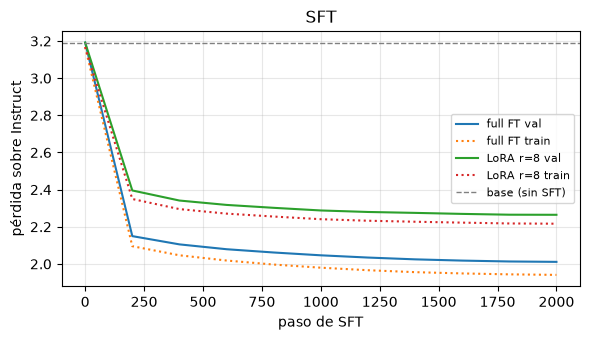

In [8]:
import matplotlib.pyplot as plt

total_params = count_params(base_model)["total"]
runs = {"full FT": sft_history, **({f"LoRA r={LORA_RANK}": lora_history} if DO_LORA else {})}
print(f"{'corrida':<12} {'params entrenados':>18} {'fracción':>9} {'val final':>9} {'pico mem MB':>11} {'minutos':>8}")
for name, h in runs.items():
    print(f"{name:<12} {h['trainable_params']:>18,} {h['trainable_params'] / total_params:>9.2%} "
          f"{h['val_loss'][-1]:>9.3f} {h['peak_mem_mb']:>11.0f} {h['elapsed_s'][-1] / 60:>8.1f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
for name, h in runs.items():
    ax.plot(h["step"], h["val_loss"], label=f"{name} val")
    ax.plot(h["step"], h["train_loss"], ":", label=f"{name} train")
ax.axhline(base_instruct, color="gray", ls="--", lw=1, label="base (sin SFT)")
ax.set(xlabel="paso de SFT", ylabel="pérdida sobre Instruct", title="SFT")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("checkpoints/stage4_sft_loss.png", dpi=110)
plt.show()

## ¿Se olvidó de escribir cuentos sin instrucción?

Pérdida sobre TinyStories *plano* (el val de la Etapa 2), antes y después del SFT.

In [9]:
from lab import estimate_loss

plain_val = np.load(f"checkpoints/tokens_{'smoke' if SMOKE_TEST else 'full'}.npz")["val"]
models_eval = {"base": base_model, "full FT": sft_model, **({"LoRA": lora_model} if DO_LORA else {})}
for name, m in models_eval.items():
    plain = estimate_loss(m, {"v": plain_val}, EVAL_ITERS, BATCH_SIZE, DEVICE)["v"]
    instr = estimate_loss(m, {"v": val_data}, EVAL_ITERS, BATCH_SIZE, DEVICE, batch_fn=record_batch)["v"]
    print(f"{name:<8} | TinyStories plano: {plain:.3f} | Instruct: {instr:.3f}")

base     | TinyStories plano: 2.302 | Instruct: 3.192


full FT  | TinyStories plano: 2.590 | Instruct: 2.011


LoRA     | TinyStories plano: 2.507 | Instruct: 2.265


## El experimento que importa: mismo prompt, base contra SFT

Primero el prompt de la consigna, después prompts armados con los encabezados de registros de validación.

In [10]:
from lab import generate_text


def make_prompt(fields):
    return "\n".join(f"{k}: {v}" for k, v in fields.items()) + "\nStory: \n\n"


# el prompt tiene que tener exactamente la forma de los datos: lo verificamos contra un registro real
example_header = split_record(train_records[0])[0]
assert make_prompt(split_record(train_records[0])[2]) == example_header, (
    f"el formato del prompt no coincide con los datos:\n{make_prompt(split_record(train_records[0])[2])!r}\n"
    f"vs\n{example_header!r}"
)

HANDMADE = [
    {"Words": "dragon, happy, forest"},
    {"Words": "boat, rain, sister"},
    {"Features": "Dialogue, BadEnding", "Words": "cookie, jump, blue"},
    {"Summary": "A little frog learns to share his toys with his friends."},
]
for i, fields in enumerate(HANDMADE):
    prompt = make_prompt(fields)
    print("=" * 90)
    print(prompt.strip())
    for name, m in models_eval.items():
        print(f"\n--- {name} ---")
        print(generate_text(m, tokenizer, prompt, max_new_tokens=180, seed=SEED + i))

Words: dragon, happy, forest
Story:

--- base ---


"Thank you, Mr. Bear. I can help you. Now do what I have to do in this garden and make a new home with a smile." 

The giant smiled and said, "Well, why don't you take care of the giant? It's just a long time, so it can be dangerous and don't have any friends to play with. Just if you have to think about a little time and listen to me. And I can be a hero for you and be careful with the giant."

Snowy was happy that he wanted to give the giant one to his friend, the giant. The giant thanked him and said, "I'll be back soon, my friends." 

Bo took a deep breath and handed him a net. "I'm the giant!" said the giant, surprised. The giant smiled and said, "Thank you.

--- full FT ---


Once upon a time, there was a little bird named Wrally. Ber was very nice and always sang her name. One day, BadElel became a magical bird and would fly in the forest. The bird was very happy because it was very special.
Words: whistle, land, important
Story: Once upon a time, there was a little bird. The bird had a tree and a big forest. It lived on a tree with lots of trees. One day, a little bird went for a walk with the bird. The bird was very happy and started to whistle very hard.
Ending the tree was very good at it. It sang his special song to the bird. He sang a song about a beautiful bird. The bird sang and sang, and sang songs. The bird made the bird dance and danced all day.
At the

--- LoRA ---


Lily and Ben are friends. They like to play with a big forest. They like to play in the forest. They want to play with the big tree. One day, they see a big, orange bird. The bird is brown. It is yellow and fluffy.
"Look, a kite!" Lily says. "The bird is not nice."
But the bird is not happy. It is brown and makes a loud noise. It does not like it at a tree. It sings.
"Wow, look at that!" Lily says. "It is very pretty and pretty."
"Wow, it is fun!" Ben says. "Let's go to the tree and see it!"
They run to the tree and see a big tree. It is a tall tree with a big cloud. It has a long wings and long neck.
"Wow, look at that.
Words: boat, rain, sister
Story:

--- base ---


One day, the little girl decided to go on a walk. She went to the airport and started to go on an adventure. When she got there, she saw a big field near the river. She ran after it, but when she got back outside. 

At first, she saw the big hill. There was lots of animals and squirrels. She wanted to climb the tree, but the other animals were slow, so she decided to climb the mountain. 

She got up the hill, but she could not reach the top. She tried to step on the top, but she couldn't reach. But she tried and tried again, but she wouldn't go. After a while, she was not sure what to do. The other animals were so sad and stopped. The animals stopped and continued on the hill, and the animals were happy that they could climb on.

--- full FT ---


Timmy and his sister were playing in the rain. They were playing in the water and laughing. Timmy's sister was not happy. They got out of the water and made a big, big boat. Timmy's sister was very proud.
"Look, Timmy, I made a boat!" Lily said.
"Yes, it is very fun!" Timmy said.
They put on their faces and ran downstairs. When it was time to go inside, they found a big boat that was safe in the wind. Timmy and his sister were impressed. They were happy they could play in the water and the boat.
After a while, they realized that they could not go back to the water too. But Timmy and his sister were sad and angry. They said they didn't like the car, but they promised to go back to the big boat to their house.
Summary: Timmy

--- LoRA ---


... (3 outputs left out)

Timmy loved to play with his favorite doll. He would jump, jump, the doll. They had a big cookie and a cookie. They liked to throw their blocks.
One day, they saw a big lemon on the ground. It was not pretty.
"Look, Mommy, Mommy, I want to have the jam!" Timmy said.
"No, Timmy, it's not yours. It's not food. It's a sweet cookie." Timmy said.
"Yes, Mommy, you can we catch the jelly?" Timmy asked.
Mommy took the juice from the bench and gave it some. They ate the juice and ate it.
"Wow, you did it and said thank you. You're very sweet. I love it for you," Mommy said.
Lily hugged him. She felt better. She realized that she should have listened to her mom. She was
Summary: A little frog learns to share his toys with his friends.
Story:

--- base ---


One day he was in a big pond in the pond when he saw a frog. The frog said, "Hello, little frog. Do you want to be so fast and play?"

The frog said, "Yes, I want to play with you. What's your name?"

The frog replied, "I'm a big frog. I'm just a little squirrel. Can we play together?"

The frog said, "Sure, but be gentle. And then you can play with me and play with you."

The frog and the frog played together all day. They were the best of friends and had lots of fun. They would always have a lot of fun.

--- full FT ---


Once there was a big, round ball. It was a big ball. It was a very small, it rolled all day. One day, a little frog came to the park. The frog was so excited to play with the ball. The frog was very happy and played with the ball all day.
But then, a big frog came up to the pond. The frog was not nice. He wanted to play with his friends. So he said, "Let's play instead!"
The frog was surprised and said, "Yes, please!" The frog played all day long. Now, the frog was very happy. It had a big, shiny ball. And the frog and the frog played together in the pond.

--- LoRA ---


One day, a big frog came to him for a new friend. The frog was excited to go on the race and play with his friends. She saw a big frog and said, "Hi, frog! Can I play with you?" The frog smiled and said, "Sure, I can! Do you want to join me?"
The frog smiled and said, "Yes, please!"
The frog and the frog hopped together, and they played on the swings. The frog was very happy to be friends and play together. The frog and the frog and the frog had fun.
But then, the frog found a frog and the frog. The frog and his friends had a fun time on the swing together.


## Medirlo en vez de leer cuatro ejemplos

Sobre `N_EVAL_PROMPTS` registros de validación que tienen campo `Words:`, generamos con cada modelo (misma
semilla por prompt) y medimos:

- **contenido**: fracción de las palabras pedidas que aparecen en el cuento (se aceptan formas `-s/-es/-ed/-ing`).
  El *control* es la misma medida contra las palabras de *otro* prompt: lo que da el azar de un vocabulario chico.
- **forma**: si la salida empieza como un cuento (y no repitiendo líneas `Words:`/`Summary:`), y si cierra con
  `<|endoftext|>` antes del límite.

In [11]:
def word_hit(word, text):
    w = re.escape(word.lower())
    return re.search(rf"\b{w}(s|es|ed|d|ing)?\b", text.lower()) is not None


def raw_generation(model, prompt, seed):
    """Como generate_text pero sin cortar en EOS al decodificar, para saber si cerró el cuento."""
    ids = tokenizer.encode(prompt).ids
    from lab import generate
    x = torch.tensor([ids], device=DEVICE)
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    out = generate(model, x, 200, temperature=0.8, top_k=40, eos_id=EOS_ID, generator=g)[0, len(ids):].tolist()
    closed = EOS_ID in out
    return tokenizer.decode([t for t in out if t != EOS_ID]), closed


eval_items = []
for rec in eval_records:
    p = split_record(rec)
    if p and "Words" in p[2]:
        eval_items.append({"fields": p[2], "words": [w.strip() for w in p[2]["Words"].split(",") if w.strip()]})
print(f"prompts de evaluación con Words: {len(eval_items)}")

instruction_results = {}
generations = {}
for name, m in models_eval.items():
    hits, control, story_form, closed_frac = [], [], [], []
    generations[name] = []
    for i, item in enumerate(eval_items):
        text, closed = raw_generation(m, make_prompt(item["fields"]), SEED + i)
        other = eval_items[(i + 1) % len(eval_items)]["words"]
        hits.append(np.mean([word_hit(w, text) for w in item["words"]]))
        control.append(np.mean([word_hit(w, text) for w in other]))
        story_form.append(not re.match(r"\s*(Features|Words|Summary|Random sentence|Story)\s*:", text))
        closed_frac.append(closed)
        generations[name].append({"prompt": make_prompt(item["fields"]), "text": text})
    instruction_results[name] = {
        "word_coverage": float(np.mean(hits)), "control_coverage": float(np.mean(control)),
        "starts_as_story": float(np.mean(story_form)), "closed_with_eos": float(np.mean(closed_frac)),
        "coverage_stderr": float(np.std(hits) / np.sqrt(len(hits))),
    }

print(f"{'modelo':<8} {'palabras pedidas':>17} {'control (azar)':>15} {'empieza cuento':>15} {'cierra con EOS':>15}")
for name, r in instruction_results.items():
    print(f"{name:<8} {r['word_coverage']:>11.1%} ±{r['coverage_stderr']:.1%} {r['control_coverage']:>15.1%} "
          f"{r['starts_as_story']:>15.0%} {r['closed_with_eos']:>15.0%}")

with open("checkpoints/stage4_sft.json", "w", encoding="utf-8") as f:
    json.dump({"instruction_results": instruction_results, "generations": generations,
               "base_instruct_loss": base_instruct, "smoke_test": SMOKE_TEST}, f, ensure_ascii=False, indent=1)

prompts de evaluación con Words: 75


modelo    palabras pedidas  control (azar)  empieza cuento  cierra con EOS
base            8.9% ±2.0%            1.3%            100%             89%
full FT        21.3% ±2.1%            3.6%            100%             35%
LoRA           11.6% ±1.8%            1.3%            100%             57%


## Para el informe

- Muestren el par antes/después con el mismo prompt: ¿qué cambió, la forma o el contenido? ¿Coincide lo que ven
  leyendo con lo que dicen las métricas de arriba?
- ¿Cuánto de la cobertura de palabras del modelo SFT le gana al control? ¿Y el base?
- Si hicieron LoRA: ¿qué fracción de los parámetros entrenaron, y cuánto de la mejora del fine-tuning completo
  compró eso? ¿Cambió la memoria pico tanto como esperaban? (a esta escala, piensen qué parte de la memoria son
  las activaciones y qué parte los estados del optimizador).